# Kerala Private Bus Accident Analysis
### Data Analysis Project using Python (pandas + matplotlib)

**Aim:** Study private bus accidents in Kerala using the data in `kerala_private_bus_accident_powerbi_data_pack.xlsx`.

**Questions we will answer**
1. Did private bus accidents go up or down from 2024 to 2025?
2. How do private buses compare with other buses (KSRTC, school bus, etc.)?
3. What is the trend of all road accidents in Kerala?
4. Which districts have the most bus accidents?
5. What do the news-reported accidents tell us (district, crash type, injuries)?

**Steps followed**
1. Import libraries
2. Load the data
3. Understand the data
4. Clean the data
5. Analyse and visualise
6. Conclusion

## Step 1: Import the libraries
* **pandas**: to read and work with tables (rows and columns)
* **matplotlib**: to draw charts

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Make every chart the same size
plt.rcParams["figure.figsize"] = (9, 4.5)

## Step 2: Load the data
The Excel file has several **sheets** (tabs). We'll read the 4 sheets that hold the data.

| Sheet | What it contains |
|---|---|
| `Official_Vehicle_Annual` | Official accident numbers for each bus type, 2024 and 2025 |
| `State_Annual_Context` | Total road accidents in all of Kerala |
| `District_Bus_2024` | Bus accidents in each district (2024) |
| `Event_Reports` | 28 bus accidents reported in the news |

In [2]:
file = "kerala_private_bus_accident_powerbi_data_pack.xlsx"

official = pd.read_excel(file, sheet_name="Official_Vehicle_Annual")
state    = pd.read_excel(file, sheet_name="State_Annual_Context")
district = pd.read_excel(file, sheet_name="District_Bus_2024")
events   = pd.read_excel(file, sheet_name="Event_Reports")

print("Data loaded successfully!")

Data loaded successfully!


## Step 3: Understand the data
We'll use some basic pandas commands:
* `.head()` shows the first 5 rows
* `.shape` gives (number of rows, number of columns)
* `.columns` lists the column names
* `.info()` shows the data type of each column and how many values are filled in

In [3]:
official.head()

,Year,Vehicle_Type,Accident_Count,Fatal_Accident_Cases,Grievous_Injury_Cases,Minor_Injury_Cases,Non_Injury_Cases,Persons_Died,Persons_Grievous_Injury,Persons_Minor_Injury,Persons_Total,Classification
0,2024,Private Bus,2443,255,1287,514,387,258,1482,1163,2903,Kerala Police PDF: impact-vehicle classification
1,2024,KSRTC Bus,772,124,425,126,97,147,523,388,1058,Kerala Police PDF: impact-vehicle classification
2,2024,Government Department Bus,68,12,44,10,2,12,46,14,72,Kerala Police PDF: impact-vehicle classification
3,2024,Mini Bus,296,34,173,63,26,36,226,194,456,Kerala Police PDF: impact-vehicle classification
4,2024,School Bus,150,12,107,21,10,12,117,63,192,Kerala Police PDF: impact-vehicle classification


In [4]:
print("Official table shape :", official.shape)
print("State table shape    :", state.shape)
print("District table shape :", district.shape)
print("Events table shape   :", events.shape)

Official table shape : (12, 12)
State table shape    : (3, 6)
District table shape : (20, 6)
Events table shape   : (28, 18)


In [5]:
events.columns

Index(['Event_ID', 'Accident_Date', 'District', 'Location', 'Route_or_Road',
       'Vehicle_Class', 'Crash_Type', 'Reported_Factor_or_Cause',
       'Speed_Mention', 'Overtaking_Mention', 'Deaths', 'Injured_Min',
       'Injured_Max', 'Affected_Persons_Reported', 'Casualty_Notes',
       'News_Source', 'Source_URL', 'Data_Quality_Notes'],
      dtype='object')

In [6]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Event_ID                   28 non-null     object        
 1   Accident_Date              28 non-null     datetime64[ns]
 2   District                   28 non-null     object        
 3   Location                   28 non-null     object        
 4   Route_or_Road              28 non-null     object        
 5   Vehicle_Class              28 non-null     object        
 6   Crash_Type                 28 non-null     object        
 7   Reported_Factor_or_Cause   28 non-null     object        
 8   Speed_Mention              28 non-null     object        
 9   Overtaking_Mention         28 non-null     object        
 10  Deaths                     27 non-null     float64       
 11  Injured_Min                26 non-null     float64       
 12  Injured_Ma

### Checking for missing values
`.isnull().sum()` counts the empty cells in each column.

In [7]:
events.isnull().sum()

Event_ID                     0
Accident_Date                0
District                     0
Location                     0
Route_or_Road                0
Vehicle_Class                0
Crash_Type                   0
Reported_Factor_or_Cause     0
Speed_Mention                0
Overtaking_Mention           0
Deaths                       1
Injured_Min                  2
Injured_Max                  5
Affected_Persons_Reported    5
Casualty_Notes               0
News_Source                  0
Source_URL                   0
Data_Quality_Notes           0
dtype: int64

**Observation:** A few columns, like `Deaths` and `Injured_Max`, have empty cells. This happens when the newspaper didn't report the number. An empty cell means **"unknown", not 0**, so we won't fill these with zero.

In [8]:
# describe() gives quick statistics: count, mean, min, max ...
official.describe()

,Year,Accident_Count,Fatal_Accident_Cases,Grievous_Injury_Cases,Minor_Injury_Cases,Non_Injury_Cases,Persons_Died,Persons_Grievous_Injury,Persons_Minor_Injury,Persons_Total
count,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000
mean,2024.500000,636.750000,70.416667,355.166667,124.666667,86.500000,74.833333,418.333333,317.500000,810.666667
std,0.522233,907.155507,90.503097,492.184340,187.806154,139.803433,93.725744,572.763371,431.443139,1094.348319
min,2024.000000,19.000000,1.000000,11.000000,5.000000,2.000000,1.000000,11.000000,8.000000,20.000000
25%,2024.000000,65.000000,11.000000,40.750000,9.000000,8.250000,12.000000,43.250000,15.500000,70.000000
50%,2024.500000,225.000000,25.000000,140.000000,45.500000,19.000000,26.000000,172.000000,168.500000,366.500000
75%,2025.000000,780.500000,115.750000,434.750000,129.000000,92.500000,130.500000,528.250000,371.500000,1040.750000
max,2025.000000,2543.000000,255.000000,1428.000000,516.000000,387.000000,258.000000,1676.000000,1229.000000,3143.000000


## Step 4: Clean the data

**4.1 Fix the date column.** We convert `Accident_Date` to a proper date type, then make a new `Year` column from it.

In [9]:
events["Accident_Date"] = pd.to_datetime(events["Accident_Date"])
events["Year"] = events["Accident_Date"].dt.year

events[["Event_ID", "Accident_Date", "Year", "District"]].head()

,Event_ID,Accident_Date,Year,District
0,EVT-001,2024-11-15,2024,Palakkad
1,EVT-002,2025-01-08,2025,Ernakulam
2,EVT-003,2025-02-26,2025,Malappuram
3,EVT-004,2025-03-05,2025,Thiruvananthapuram
4,EVT-005,2025-05-19,2025,Idukki


**4.2 Remove a duplicate.** The dataset notes say **EVT-022** and **EVT-023** are probably the **same accident** (same day, same area in Kollam), so we remove EVT-023.

In [10]:
print("Rows before:", len(events))

events = events[events["Event_ID"] != "EVT-023"]

print("Rows after :", len(events))

Rows before: 28
Rows after : 27


**4.3 Combine City and Rural districts.** In the district table, some districts are split into two police areas, for example *"Kozhikode City"* and *"Kozhikode Rural"*. We remove the words "City" and "Rural" so both rows get the same district name.

In [11]:
district["District"] = district["District_Unit"].str.replace(" City", "").str.replace(" Rural", "")

district[["District_Unit", "District"]].head(6)

,District_Unit,District
0,Thiruvananthapuram City,Thiruvananthapuram
1,Thiruvananthapuram Rural,Thiruvananthapuram
2,Kollam City,Kollam
3,Kollam Rural,Kollam
4,Pathanamthitta,Pathanamthitta
5,Alappuzha,Alappuzha


## Step 5: Analysis and Visualisation

### 5.1 Private bus accidents: 2024 vs 2025
First, we **filter** the official table to keep only the "Private Bus" rows.

In [12]:
private = official[official["Vehicle_Type"] == "Private Bus"]

private[["Year", "Accident_Count", "Persons_Died", "Persons_Grievous_Injury", "Persons_Minor_Injury"]]

,Year,Accident_Count,Persons_Died,Persons_Grievous_Injury,Persons_Minor_Injury
0,2024,2443,258,1482,1163
6,2025,2543,238,1676,1229


In [13]:
# Get the 2024 and 2025 rows separately
p2024 = private[private["Year"] == 2024].iloc[0]
p2025 = private[private["Year"] == 2025].iloc[0]

# Calculate the change
acc_change   = p2025["Accident_Count"] - p2024["Accident_Count"]
acc_percent  = acc_change / p2024["Accident_Count"] * 100

death_change  = p2025["Persons_Died"] - p2024["Persons_Died"]
death_percent = death_change / p2024["Persons_Died"] * 100

print("Accidents :", p2024["Accident_Count"], "->", p2025["Accident_Count"], f"(change {acc_percent:+.1f}%)")
print("Deaths    :", p2024["Persons_Died"], "->", p2025["Persons_Died"], f"(change {death_percent:+.1f}%)")

Accidents : 2443 -> 2543 (change +4.1%)
Deaths    : 258 -> 238 (change -7.8%)


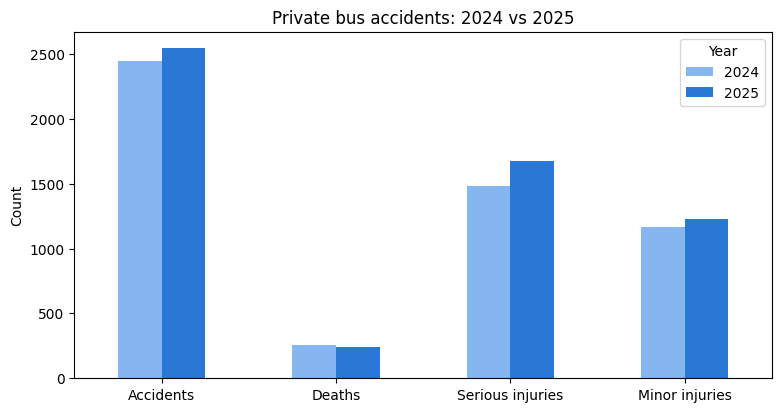

In [14]:
# Bar chart: accidents, deaths and injuries in each year
chart_data = private.set_index("Year")[["Accident_Count", "Persons_Died", "Persons_Grievous_Injury", "Persons_Minor_Injury"]]
chart_data.columns = ["Accidents", "Deaths", "Serious injuries", "Minor injuries"]

chart_data.T.plot(kind="bar", color=["#86b6ef", "#2a78d6"], rot=0)
plt.title("Private bus accidents: 2024 vs 2025")
plt.ylabel("Count")
plt.show()

**Observation**
* Private bus accidents went **up** from **2,443** to **2,543** (+4.1%).
* Deaths went **down** from **258** to **238** (-7.8%).
* Serious (grievous) injuries went **up** from **1,482** to **1,676**.

👉 Fewer people died, but more people were seriously injured.

### 5.2 Private buses vs other types of buses (2025)

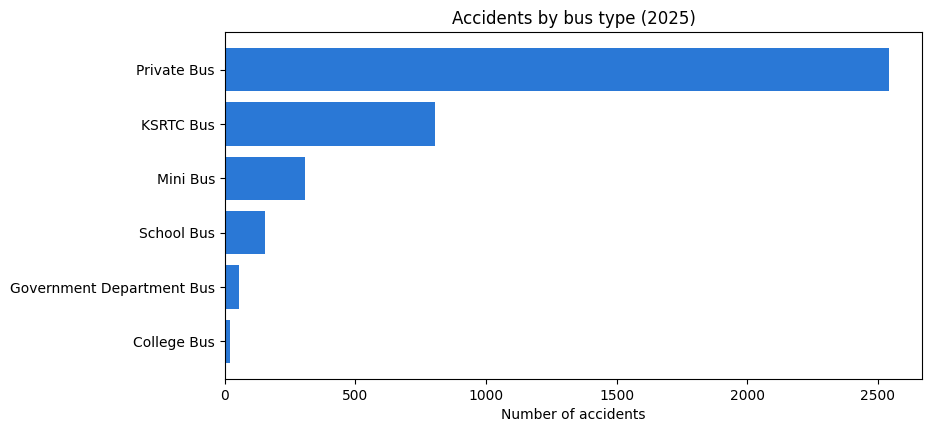

In [15]:
data_2025 = official[official["Year"] == 2025]
data_2025 = data_2025.sort_values("Accident_Count")

plt.barh(data_2025["Vehicle_Type"], data_2025["Accident_Count"], color="#2a78d6")
plt.title("Accidents by bus type (2025)")
plt.xlabel("Number of accidents")
plt.show()

In [16]:
# What percentage of bus accidents are private bus accidents?
total_bus_accidents = data_2025["Accident_Count"].sum()
private_accidents   = p2025["Accident_Count"]

print("Total bus accidents in 2025 :", total_bus_accidents)
print("Private bus accidents       :", private_accidents)
print(f"Private bus share           : {private_accidents / total_bus_accidents * 100:.1f}%")

Total bus accidents in 2025 : 3885
Private bus accidents       : 2543
Private bus share           : 65.5%


**Which bus type is more dangerous?** We make a new column: **deaths for every 100 accidents**.

In [17]:
official["Deaths_per_100"] = official["Persons_Died"] / official["Accident_Count"] * 100

table = official.pivot_table(index="Vehicle_Type", columns="Year", values="Deaths_per_100").round(1)
table

Year,2024,2025
Vehicle_Type,,
College Bus,11.1,5.3
Government Department Bus,17.6,23.2
KSRTC Bus,19.0,15.5
Mini Bus,12.2,12.1
Private Bus,10.6,9.4
School Bus,8.0,10.4


**Observation**
* Private buses are involved in about **2 out of every 3 bus accidents** (65%).
* But for every 100 accidents, **KSRTC buses cause more deaths** (15.5) than private buses (9.4) in 2025.

👉 Private buses have **more** accidents, while KSRTC accidents are **more deadly** on average.

### 5.3 All road accidents in Kerala (state trend)
⚠️ The 2026 figures cover only **January–August** (8 months). To compare fairly, we work out the **average per month**.

In [18]:
state["Months"] = [12, 12, 8]
state["Accidents_per_month"] = state["Total_Road_Accidents"] / state["Months"]

state[["Year", "Total_Road_Accidents", "Deaths", "Months", "Accidents_per_month"]].round(0)

,Year,Total_Road_Accidents,Deaths,Months,Accidents_per_month
0,2024,48834,3880,12,4070.0
1,2025,49889,3733,12,4157.0
2,2026,35873,2702,8,4484.0


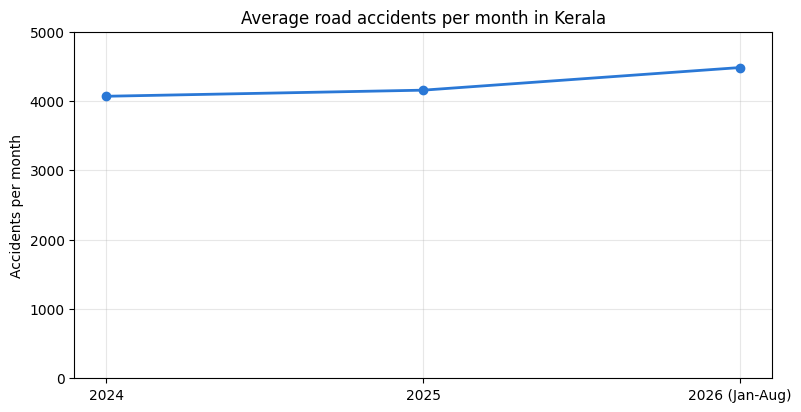

In [19]:
years = ["2024", "2025", "2026 (Jan-Aug)"]
plt.plot(years, state["Accidents_per_month"], marker="o", color="#2a78d6", linewidth=2)
plt.title("Average road accidents per month in Kerala")
plt.ylabel("Accidents per month")
plt.ylim(0, 5000)
plt.grid(alpha=0.3)
plt.show()

In [20]:
share_2025 = p2025["Accident_Count"] / state.loc[state["Year"] == 2025, "Total_Road_Accidents"].values[0] * 100
death_share_2025 = p2025["Persons_Died"] / state.loc[state["Year"] == 2025, "Deaths"].values[0] * 100

print(f"Private bus share of ALL road accidents in 2025 : {share_2025:.1f}%")
print(f"Private bus share of ALL road deaths in 2025    : {death_share_2025:.1f}%")

Private bus share of ALL road accidents in 2025 : 5.1%
Private bus share of ALL road deaths in 2025    : 6.4%


**Observation**
* Road accidents per month went up: **4,070 (2024) → 4,157 (2025) → 4,484 (2026)**.
* Private buses cause about **5%** of all road accidents but **6.4%** of all road deaths.

### 5.4 Which districts have the most bus accidents? (2024)
We use **`groupby()`** to add up the City and Rural rows for each district.

In [21]:
district_total = district.groupby("District")[["KSRTC_Buses_Involved", "Other_Buses_Composite_Involved", "Total_Bus_Involvements"]].sum()
district_total = district_total.sort_values("Total_Bus_Involvements", ascending=False)

district_total

,KSRTC_Buses_Involved,Other_Buses_Composite_Involved,Total_Bus_Involvements
District,,,
Kozhikode,57,549,606
Ernakulam,82,474,556
Thrissur,54,366,420
Thiruvananthapuram,180,150,330
Malappuram,29,271,300
Kottayam,65,212,277
Kollam,94,171,265
Kannur,22,235,257
Palakkad,18,201,219


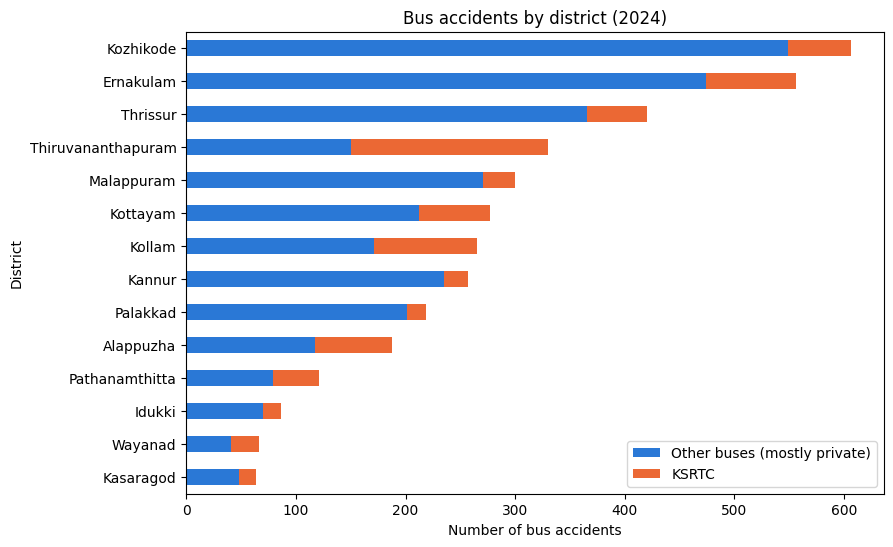

In [22]:
top = district_total.sort_values("Total_Bus_Involvements")

top[["Other_Buses_Composite_Involved", "KSRTC_Buses_Involved"]].plot(
    kind="barh", stacked=True, color=["#2a78d6", "#eb6834"], figsize=(9, 6))
plt.title("Bus accidents by district (2024)")
plt.xlabel("Number of bus accidents")
plt.legend(["Other buses (mostly private)", "KSRTC"])
plt.show()

In [23]:
print("Top 5 districts:")
print(district_total["Total_Bus_Involvements"].head(5))

Top 5 districts:
District
Kozhikode             606
Ernakulam             556
Thrissur              420
Thiruvananthapuram    330
Malappuram            300
Name: Total_Bus_Involvements, dtype: int64


**Observation**
* **Kozhikode** has the most bus accidents (606), followed by **Ernakulam** (556) and **Thrissur** (420).
* In northern districts like Kozhikode, Malappuram and Kannur, almost all bus accidents involve private-type buses.
* In **Thiruvananthapuram**, KSRTC buses are involved in more accidents than other buses, since KSRTC runs most services there.

*Note: "Other buses" includes private buses plus a few other kinds, so it isn't exactly the same as "Private Bus".*

### 5.5 News-reported accidents (Nov 2024 – Nov 2026)
This sheet has **27 accidents** reported in newspapers (after removing the duplicate). It's a **sample** and doesn't include every accident.

**Accidents by year**

In [24]:
events["Year"].value_counts().sort_index()

Year
2024     1
2025    11
2026    15
Name: count, dtype: int64

**Accidents by district.** `value_counts()` counts how many times each value appears.

District
Thrissur              9
Ernakulam             5
Malappuram            3
Kozhikode             2
Idukki                2
Kannur                2
Palakkad              1
Thiruvananthapuram    1
Kollam                1
Kottayam              1
Name: count, dtype: int64


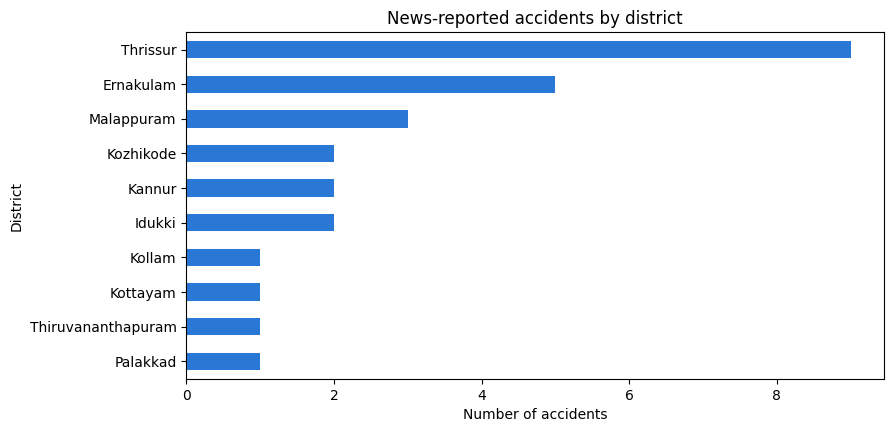

In [25]:
district_counts = events["District"].value_counts()
print(district_counts)

district_counts.sort_values().plot(kind="barh", color="#2a78d6")
plt.title("News-reported accidents by district")
plt.xlabel("Number of accidents")
plt.show()

**Type of vehicles involved**

In [26]:
events["Vehicle_Class"].value_counts()

Vehicle_Class
Private route bus                   14
Two private route buses              3
Private limited-stop bus             2
Private route bus + lorry            1
Private bus + KSRTC                  1
Private route bus + scooter          1
Private mini tourist bus             1
Private route bus + college bus      1
Private route bus + KSRTC            1
Private route bus + tanker lorry     1
KSRTC bus + private route bus        1
Name: count, dtype: int64

**Deaths and injuries**

In [27]:
total_deaths  = events["Deaths"].sum()
total_injured = events["Injured_Min"].sum()
fatal_accidents = (events["Deaths"] > 0).sum()

print("Total deaths reported           :", int(total_deaths))
print("Accidents with at least 1 death :", fatal_accidents)
print("Total injured (at least)        :", int(total_injured))
print("Average injured per accident    :", round(events["Injured_Min"].mean(), 1))

Total deaths reported           : 6
Accidents with at least 1 death : 5
Total injured (at least)        : 322
Average injured per accident    : 12.9


**Top 5 accidents with the most injuries**

In [28]:
events.sort_values("Injured_Min", ascending=False)[["Event_ID", "Accident_Date", "District", "Crash_Type", "Injured_Min", "Deaths"]].head(5)

,Event_ID,Accident_Date,District,Crash_Type,Injured_Min,Deaths
1,EVT-002,2025-01-08,Ernakulam,Bus hit tree after losing control,38.0,0.0
21,EVT-022,2026-08-30,Kollam,Collision between private buses,27.0,0.0
18,EVT-019,2026-07-26,Malappuram,Overturn after hitting divider,26.0,1.0
24,EVT-025,2026-09-12,Thrissur,KSRTC bus rear-ended private bus,25.0,0.0
23,EVT-024,2026-09-04,Ernakulam,Bus hit concrete toll-plaza pillar,23.0,0.0


**Was speeding mentioned?**

In [29]:
# Count rows where the text contains "Yes" or "police"
speed = events["Speed_Mention"].str.contains("Yes|police").sum()
print("Accidents where speeding was mentioned:", speed, "out of", len(events))

events["Speed_Mention"].value_counts()

Accidents where speeding was mentioned: 12 out of 27


Speed_Mention
Not stated                                  14
Yes - reported, not officially confirmed     1
Yes - allegation against KSRTC driver        1
Yes - eyewitness report                      1
Yes - preliminary report                     1
No                                           1
Yes - attributed to authorities              1
Speed mentioned by police                    1
Yes - MVD report                             1
Yes - police reports                         1
Yes - local allegation                       1
Yes - reported                               1
Yes - police statement                       1
Yes - MVD confirmed                          1
Name: count, dtype: int64

**Observation**
* **Thrissur** has the most news-reported accidents (9 of 27), followed by **Ernakulam** (5).
* Most accidents involved a **private route bus** on its own (losing control, hitting a tree, overturning).
* **6 people died** in 5 accidents, and **more than 300 people were injured**.
* Many crashes injured **15 or more** people at once, because buses carry a lot of passengers.
* Speeding was mentioned in **12 of 27** reports, but only a couple were **officially confirmed** by the MVD (Motor Vehicles Department).

## Step 6: Conclusion

| # | Finding |
|---|---|
| 1 | Private buses are involved in about **65% of bus accidents** in Kerala. |
| 2 | From 2024 to 2025, private bus **accidents rose 4.1%**, **deaths fell 7.8%**, and **serious injuries rose 13.1%**. |
| 3 | **KSRTC** accidents are more **deadly** per accident than private bus accidents. |
| 4 | Private buses cause **~5% of all road accidents** but **6.4% of road deaths** in Kerala. |
| 5 | Road accidents in Kerala are **increasing** (monthly average is higher in 2026). |
| 6 | **Kozhikode, Ernakulam and Thrissur** have the most bus accidents. |
| 7 | In news reports, **Thrissur** comes up the most, and **speeding** is the most commonly mentioned cause. |

### Suggestions
* Stricter **speed checks** on private buses, especially on busy routes like Kozhikode–Thrissur.
* Make sure bus **doors are closed** while moving (some passengers fell out).
* Regular checks of **tyres, brakes and speed governors**.

### Limitations
* The official data only gives **yearly totals**, not every individual accident.
* The news data is only a **sample** of 27 accidents, not a complete list.
* Causes in news reports are sometimes **not confirmed** by the police.

## Python functions used in this project (quick reference)

| Function | What it does |
|---|---|
| `pd.read_excel()` | Reads a sheet from an Excel file |
| `.head()` | Shows the first 5 rows |
| `.shape` | Gives (rows, columns) |
| `.info()` | Shows column types and missing values |
| `.isnull().sum()` | Counts the empty cells in each column |
| `.describe()` | Gives basic statistics |
| `pd.to_datetime()` | Converts text to a date |
| `df[df["col"] == value]` | Filters rows |
| `.str.replace()` | Replaces text inside a column |
| `.groupby().sum()` | Adds up values for each group |
| `.value_counts()` | Counts how often each value appears |
| `.sort_values()` | Sorts the table |
| `.pivot_table()` | Rearranges data into a summary table |
| `.plot()` / `plt.bar()` / `plt.plot()` | Draws charts |